# MIA multi-omics pipeline: a guided run on toy data

Does **maternal immune activation (MIA)** during pregnancy change the lipids,
metabolites and proteins of the offspring's brain? The study has 20 mice
(10 MIA, 10 saline control) and 3 brain regions each, so 60 samples, with
lipidomics, metabolomics and proteomics measured on every sample.

This notebook runs the whole analysis pipeline from raw files to multi-omics
integration. **The data here are simulated.** `mia_multiomics.toy_data` writes
files with exactly the same layout as the real core-facility deliverables, and
plants a known truth in them:

| Planted in the toy data | What the pipeline should find |
|---|---|
| strong brain-region differences in all omics | region dominates every analysis (positive control) |
| **no MIA effect at all** | no robust MIA hit (negative control) |
| litter (cage) and mouse random effects | mouse-level tests are too optimistic; litter-level tests are honest |
| two shared within-region programmes ("myelin", "energy") + sex-linked proteins | MOFA+ factors shared across omics |
| two outlying samples (sample numbers 10 and 45) | flagged by the outlier screens |

**Speed.** `Settings.fast` uses small permutation and bootstrap counts, so the
whole notebook runs in about 15-20 minutes. Set `RERUN = False` to reload
tables that are already in `results/` instead of recomputing them.
`Settings.full` reproduces the thesis-size run.

## 0. Setup

In [1]:
import sys, time
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))           # not needed after `pip install -e .`

from mia_multiomics import config, inputs
from mia_multiomics.config import Settings
from mia_multiomics.toy_data import write_toy_dataset
from mia_multiomics.stages import (qc, noise_floor, feature_modules, outliers, differential, sensitivity,
                                   region_persistence, asca, effect_sizes, integration, vendor_figures)

settings = Settings.fast(PROJECT)    # Settings.full(PROJECT) for the real, slow run
RERUN = True                         # False: reuse tables already written to results/

pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)

def show(*parts, width=650):
    """Display a figure written by the pipeline: show('lipidomics', '01_qc', 'pca', 'figures', 'x.png')."""
    display(Image(filename=str(settings.results_dir.joinpath(*parts)), width=width))

def step(name, function, check_file=None):
    """Run one pipeline step (or skip it if RERUN is False and its output exists) and time it."""
    if not RERUN and check_file is not None and (settings.results_dir / check_file).exists():
        print(f"{name}: using saved results")
        return None
    start = time.time()
    result = function()
    print(f"{name}: {time.time() - start:.0f} s")
    return result

def table(*parts):
    return pd.read_csv(settings.results_dir.joinpath(*parts))

settings

Settings(project_root=PosixPath('/home/claude/new/multi-omics-integration-pipeline'), seed=20261017, n_permutations=99, n_asca_permutations=99, n_bootstraps=100, n_split_halves=100, n_null_replicates=40, n_isolation_forest_seeds=5, n_isolation_forest_trees=50, n_power_datasets=10, n_power_permutations=29, n_feature_bootstraps=100, n_module_bootstraps=20, n_module_nulls=20, mofa_factors=6, mofa_iterations=500, mofa_seeds=5, mofa_shuffles=3, n_cross_omics_shuffles=20, n_cross_omics_bootstraps=10, n_mouse_permutations=999, use_r=False, quick=True)

## 1. The input files

`write_toy_dataset` writes the five deliverables: one Excel report (sample sheet,
lipidomics, metabolomics), the cage/collection-date workbook, one Perseus export
per region for proteomics, and GO/Reactome-style gene-set files.

In [2]:
write_toy_dataset(settings.data_dir)
sorted(p.relative_to(PROJECT).as_posix() for p in settings.data_dir.rglob("*") if p.is_file())

['data/README.md',
 'data/TOY_DATA_README.txt',
 'data/lipidomics_metabolomics_report.xlsx',
 'data/proteomics_Cerebellum.txt',
 'data/proteomics_Cortex.txt',
 'data/proteomics_Hippocampus.txt',
 'data/reference/toy_go_bp_2026-10-01.gmt',
 'data/reference/toy_reactome_v97.gmt',
 'data/sample_cage_metadata.xlsx']

`inputs` parses the vendor layouts. For example, the lipidomics sheet has label
rows above its header and repeats the header before the negative-mode lipids.
Every omics comes back in the same shape: raw values, blanks, pooled-QC
(Tech-Mix) injections, a feature annotation table and the sample metadata.

In [3]:
lipids = inputs.load_lipidomics(settings)
metabolites = inputs.load_metabolomics(settings)
proteins = inputs.load_proteomics(settings)
for data in (lipids, metabolites, proteins):
    print(f"{data.name:13s} values {data.values.shape}  blanks {None if data.blanks is None else data.blanks.shape}"
          f"  techmix {None if data.techmix is None else data.techmix.shape}")
lipids.values.iloc[:5, :6]

lipidomics    values (301, 60)  blanks (301, 6)  techmix (301, 6)
metabolomics  values (120, 60)  blanks (120, 6)  techmix (120, 6)
proteomics    values (700, 60)  blanks None  techmix None


,TOY_001-01,TOY_001-02,TOY_001-03,TOY_001-04,TOY_001-05,TOY_001-06
Feature,,,,,,
AcCa(14:1),10672.635,31651.911,10121.177,17287.993,40941.880,22685.671
AcCa(15:0),4544.984,7302.828,3810.904,3167.220,9343.007,11235.923
AcCa(15:1),720580.895,465900.077,570032.533,617461.904,951774.363,589369.282
AcCa(17:0),919058.508,836826.468,501405.556,905545.164,725435.394,816915.689
AcCa(18:0),148483.717,240543.811,90853.348,100331.217,267382.986,186694.790


**The study design.** Control mice come from 2 mixed-sex litters and MIA mice
from 6 single-sex litters. Each litter was collected on one date. Pups of one
litter share a mother, a cage and a date, so they are not independent: the
experimental unit for MIA is the **litter**. With 2 vs 6 litters there are only
C(8,2) = 28 ways to assign treatment to whole litters.

In [4]:
meta = lipids.metadata
mice = meta.drop_duplicates(config.MOUSE_COL)
pd.crosstab([mice[config.CAGE_COL], mice[config.COHORT_COL]], [mice[config.GROUP_COL], mice[config.SEX_COL]])

Bio group                   MIA      Saline Control     
Sex                      Female Male         Female Male
Cage   Collection cohort                                
C10001 2024-06-11             0    0              3    3
C10002 2024-06-25             0    0              2    2
C20001 2024-06-11             0    2              0    0
C20002 2024-06-18             0    2              0    0
C20003 2024-06-18             0    1              0    0
C20004 2024-06-11             2    0              0    0
C20005 2024-06-25             2    0              0    0
C20006 2024-06-25             1    0              0    0

## 2. Preprocessing

One function, `preprocessing.preprocess`, applies the same chain to lipidomics
and metabolomics:

1. **prevalence:** drop features missing in more than 20 % of all 60 samples;
2. **blank filter:** drop features whose median signal is below 3 x the mean blank;
3. **detection limit:** set single values below max(3 x blank, floor) to missing;
4. choose the population's samples, then apply **log2** and **median normalisation**
   (per acquisition mode for metabolomics).

Nothing is imputed, and every removed feature is logged with its reason.

In [5]:
from mia_multiomics.preprocessing import preprocess
prepared = preprocess(lipids)
display(prepared.summary)
prepared.exclusions.groupby(["stage", "reason"]).size().rename("n_features").reset_index()

,omics,n_samples,n_features_input,n_after_prevalence,n_blank_dominated,n_no_detectable_value,n_features_output,n_values_below_detection,detection_floor,blank_multiplier,normalization
0,lipidomics,60,301,288,6,0,282,161,1.0,3.0,median


,stage,reason,n_features
0,blank_filter,median signal < 3 x mean blank,6
1,prevalence,missing in > 20% of all samples,13


## 3. Quality control

The QC stage writes the preprocessing log, pooled-QC reproducibility (Tech-Mix
CV), technical vs biological variance, missingness by group and class, and a
descriptive PCA. Two more QC analyses look for structure among the features:
an abundance-similarity noise floor (noisyR-style), and feature-space PCA with
co-abundance modules.

In [6]:
headlines = step("qc", lambda: [qc.run(settings, o) for o in config.VIEWS], "lipidomics/01_qc/headline.json")
step("noise floor", lambda: noise_floor.run(settings, "lipidomics"), "lipidomics/01_qc/noise_floor/candidate_thresholds.csv")
step("feature modules", lambda: [feature_modules.run(settings, o) for o in ("lipidomics", "metabolomics")],
     "metabolomics/01_qc/feature_modules/summary.csv")
pd.DataFrame([pd.read_json(settings.results_dir / o / "01_qc" / "headline.json", typ="series") for o in config.VIEWS]).set_index("omics").T

qc: 23 s


noise floor: 26 s


feature modules: 9 s


omics,lipidomics,metabolomics,proteomics
n_samples,60,60,60
n_features_input,301,120,700
n_after_prevalence,288.0,120.0,NaN
n_blank_dominated,6.0,6.0,NaN
n_no_detectable_value,0.0,0.0,NaN
n_features_output,282,114,700
n_values_below_detection,161.0,62.0,NaN
detection_floor,1.0,220.297,NaN
blank_multiplier,3.0,3.0,NaN
normalization,median,median,NaN


**The data have strong structure, and it is region.** Pooled PC1 is almost
entirely brain region. MIA explains close to nothing on any of the first five
components.

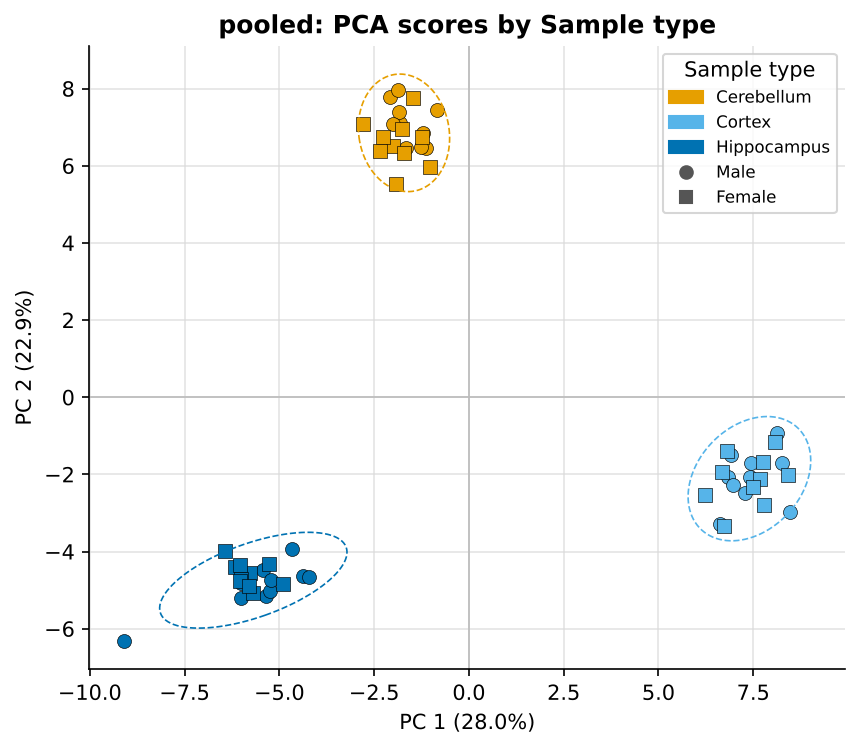

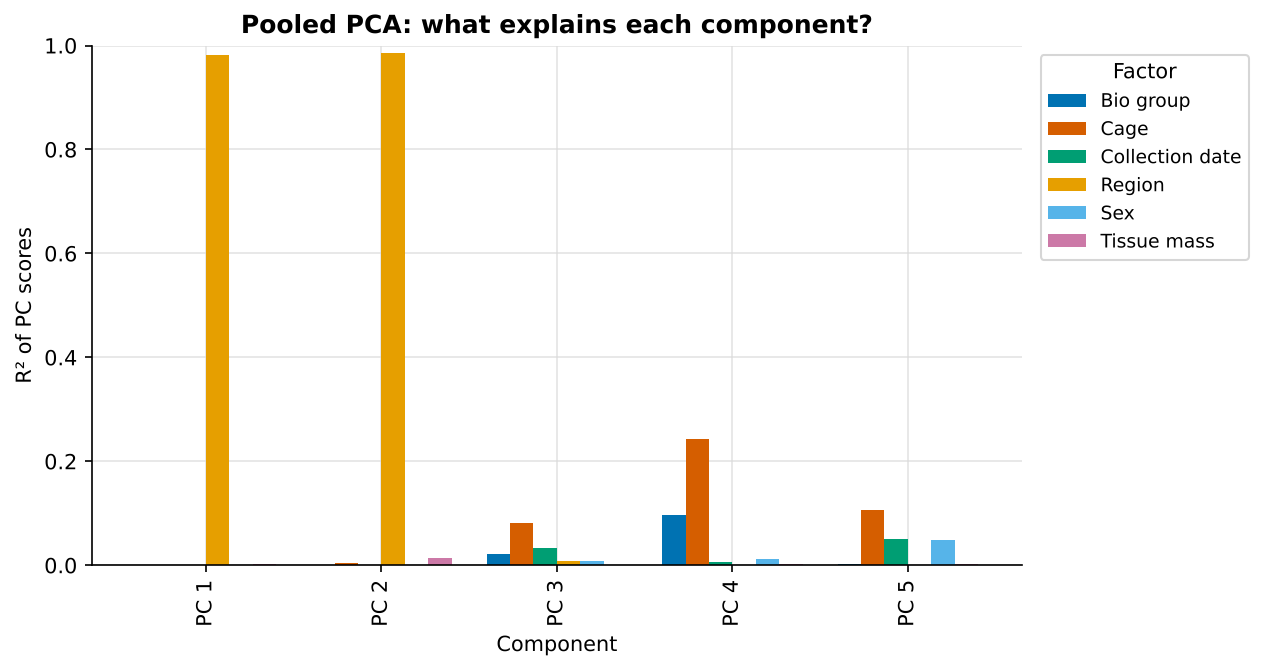

In [7]:
show("lipidomics", "01_qc", "pca", "figures", "scores_pooled_sample_type.png", width=520)
show("lipidomics", "01_qc", "pca", "figures", "score_attribution_pooled.png")

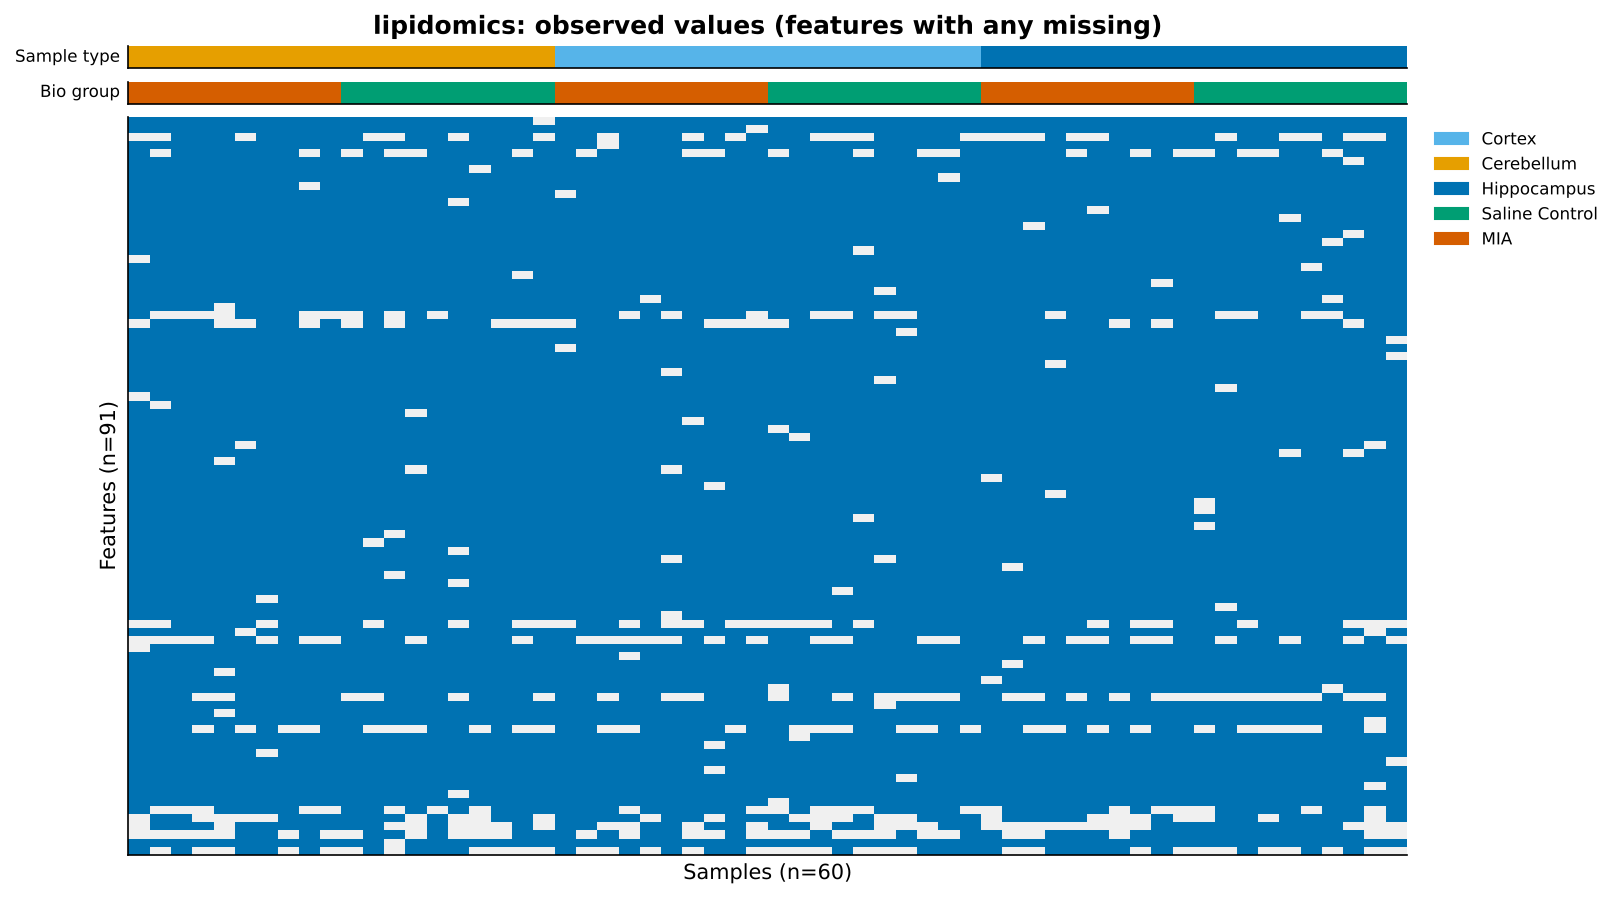

,Region,n_complete_features,feature_margin_pc1_variance,split_half_pc1,n_modules,n_reportable_modules,largest_module,largest_null_module_median,largest_module_z_vs_null
0,Cerebellum,94,0.365,-0.421,71,0,13,2.0,27.291
1,Cortex,88,0.206,0.059,79,0,3,2.0,2.765
2,Hippocampus,87,0.258,0.331,72,0,5,2.0,6.437


In [8]:
show("lipidomics", "01_qc", "missingness", "figures", "missingness_heatmap_by_region.png", width=700)
table("metabolomics", "01_qc", "feature_modules", "summary.csv")

## 4. Outliers

Two screens. Both only flag samples; nothing is deleted.

* **Regional PCA screen:** Hotelling T² and robust Mahalanobis distance in 3 PCs,
  plus DModX. The T² 95 % and 99 % flags define the only two permitted
  sensitivity populations, `t2_95` and `t2_99`. Exclusion is always per sample,
  never per mouse.
* **Calibrated ensemble:** six detector families. Every parameter is swept, and
  each setting is calibrated on simulated outlier-free data. A sample is a
  candidate only if at least two detectors flag it stably.

In [9]:
screen = step("outlier screen", lambda: [outliers.run_screen(settings, o) for o in ("lipidomics", "metabolomics")],
              "lipidomics/02_outliers/outlier_screen.csv")
screen = table("lipidomics", "02_outliers", "outlier_screen.csv")
screen.loc[screen["hotelling_t2_95_flag"], ["Sample", "Sample number", "Region", "hotelling_t2", "hotelling_t2_95_limit", "hotelling_t2_99_flag"]]

outlier screen: 4 s


,Sample,Sample number,Region,hotelling_t2,hotelling_t2_95_limit,hotelling_t2_99_flag
0,TOY_001-02,2,Cerebellum,8.421,6.82,False
20,TOY_001-10,10,Cortex,17.817,6.82,True
40,TOY_001-45,45,Hippocampus,17.828,6.82,True
41,TOY_001-24,24,Hippocampus,7.473,6.82,False


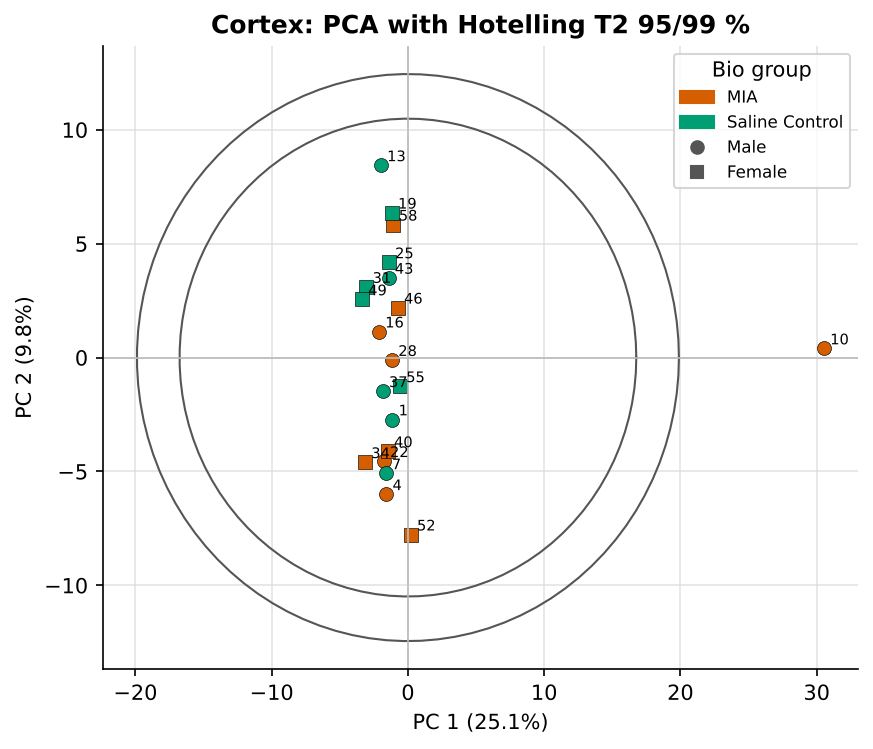

In [10]:
show("lipidomics", "02_outliers", "figures", "pca_hotelling_cortex.png", width=520)

In [11]:
step("outlier ensemble", lambda: outliers.run_ensemble(settings, "lipidomics"), "lipidomics/02_outliers/ensemble/ensemble_verdict.csv")
outliers.run_concordance(settings)
verdict = table("lipidomics", "02_outliers", "ensemble", "ensemble_verdict.csv")
verdict.loc[verdict["candidate_outlier"], ["scope", "Sample number", "stable_detector_count", "calibration_sensitive", "robust_candidate"]]

outlier ensemble: 119 s


,scope,Sample number,stable_detector_count,calibration_sensitive,robust_candidate
9,pooled,10,6,False,True
44,pooled,45,6,False,True
60,cerebellum,2,3,False,True
78,cerebellum,56,2,True,False
83,cortex,10,5,False,True
107,hippocampus,24,3,True,False
114,hippocampus,45,5,False,True


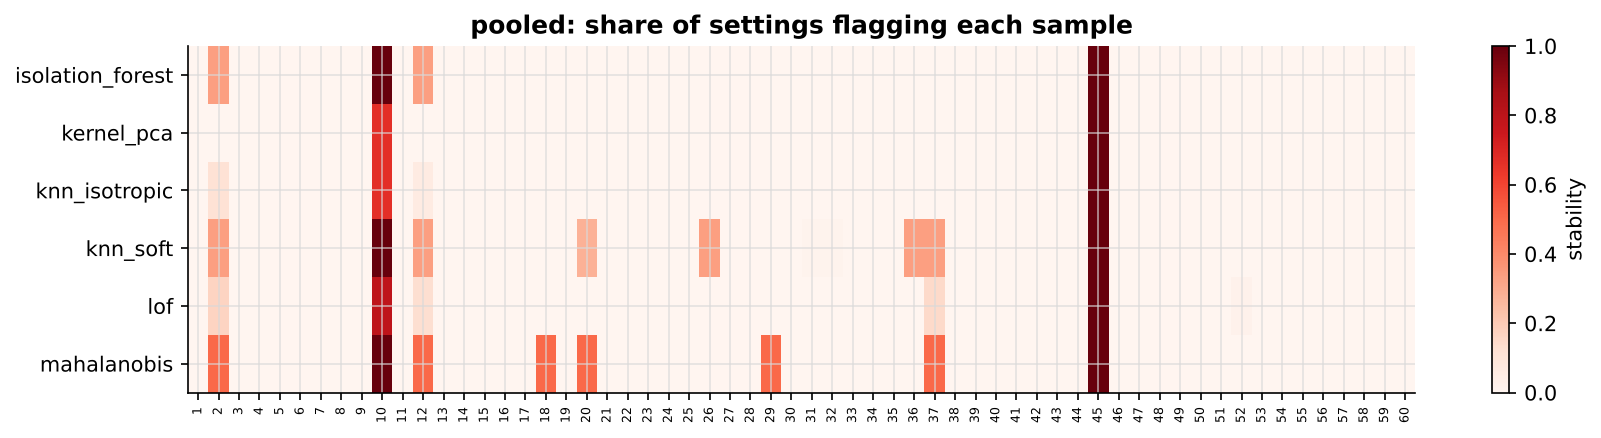

In [12]:
show("lipidomics", "02_outliers", "ensemble", "figures", "stability_pooled.png", width=700)

## 5. MIA vs control, feature by feature

For every feature and region we fit `log2 value ~ group * sex` (OLS), with
Benjamini-Hochberg FDR over the whole panel. Around this model the stage adds a
label-permutation null, the **effective** number of independent tests, residual
and influence diagnostics, the **minimum detectable effect**, and PERMANOVA and
PLS-DA checks. We run it for all three populations.

In [13]:
def run_differential():
    for omics in ("lipidomics", "metabolomics"):
        for population in config.POPULATIONS:
            differential.run(settings, omics, population)
        differential.compare_populations(settings, omics)
step("differential", run_differential, "lipidomics/03_differential/population_comparison/hits_by_population.csv")
hits = table("lipidomics", "03_differential", "population_comparison", "hits_by_population.csv")
hits.pivot_table(index=["Region", "Effect"], columns="population", values="n_fdr_hits")

differential: 172 s


population                            all60  t2_95  t2_99
Region      Effect                                       
Cerebellum  Female vs Male              0.0    0.0    0.0
            MIA vs Saline Control       0.0    0.0    0.0
            MIA x Female interaction    0.0    0.0    0.0
Cortex      Female vs Male              0.0    2.0    2.0
            MIA vs Saline Control       0.0    0.0    0.0
            MIA x Female interaction    0.0    0.0    0.0
Hippocampus Female vs Male              0.0    1.0    1.0
            MIA vs Saline Control       0.0    0.0    0.0
            MIA x Female interaction    0.0    0.0    0.0

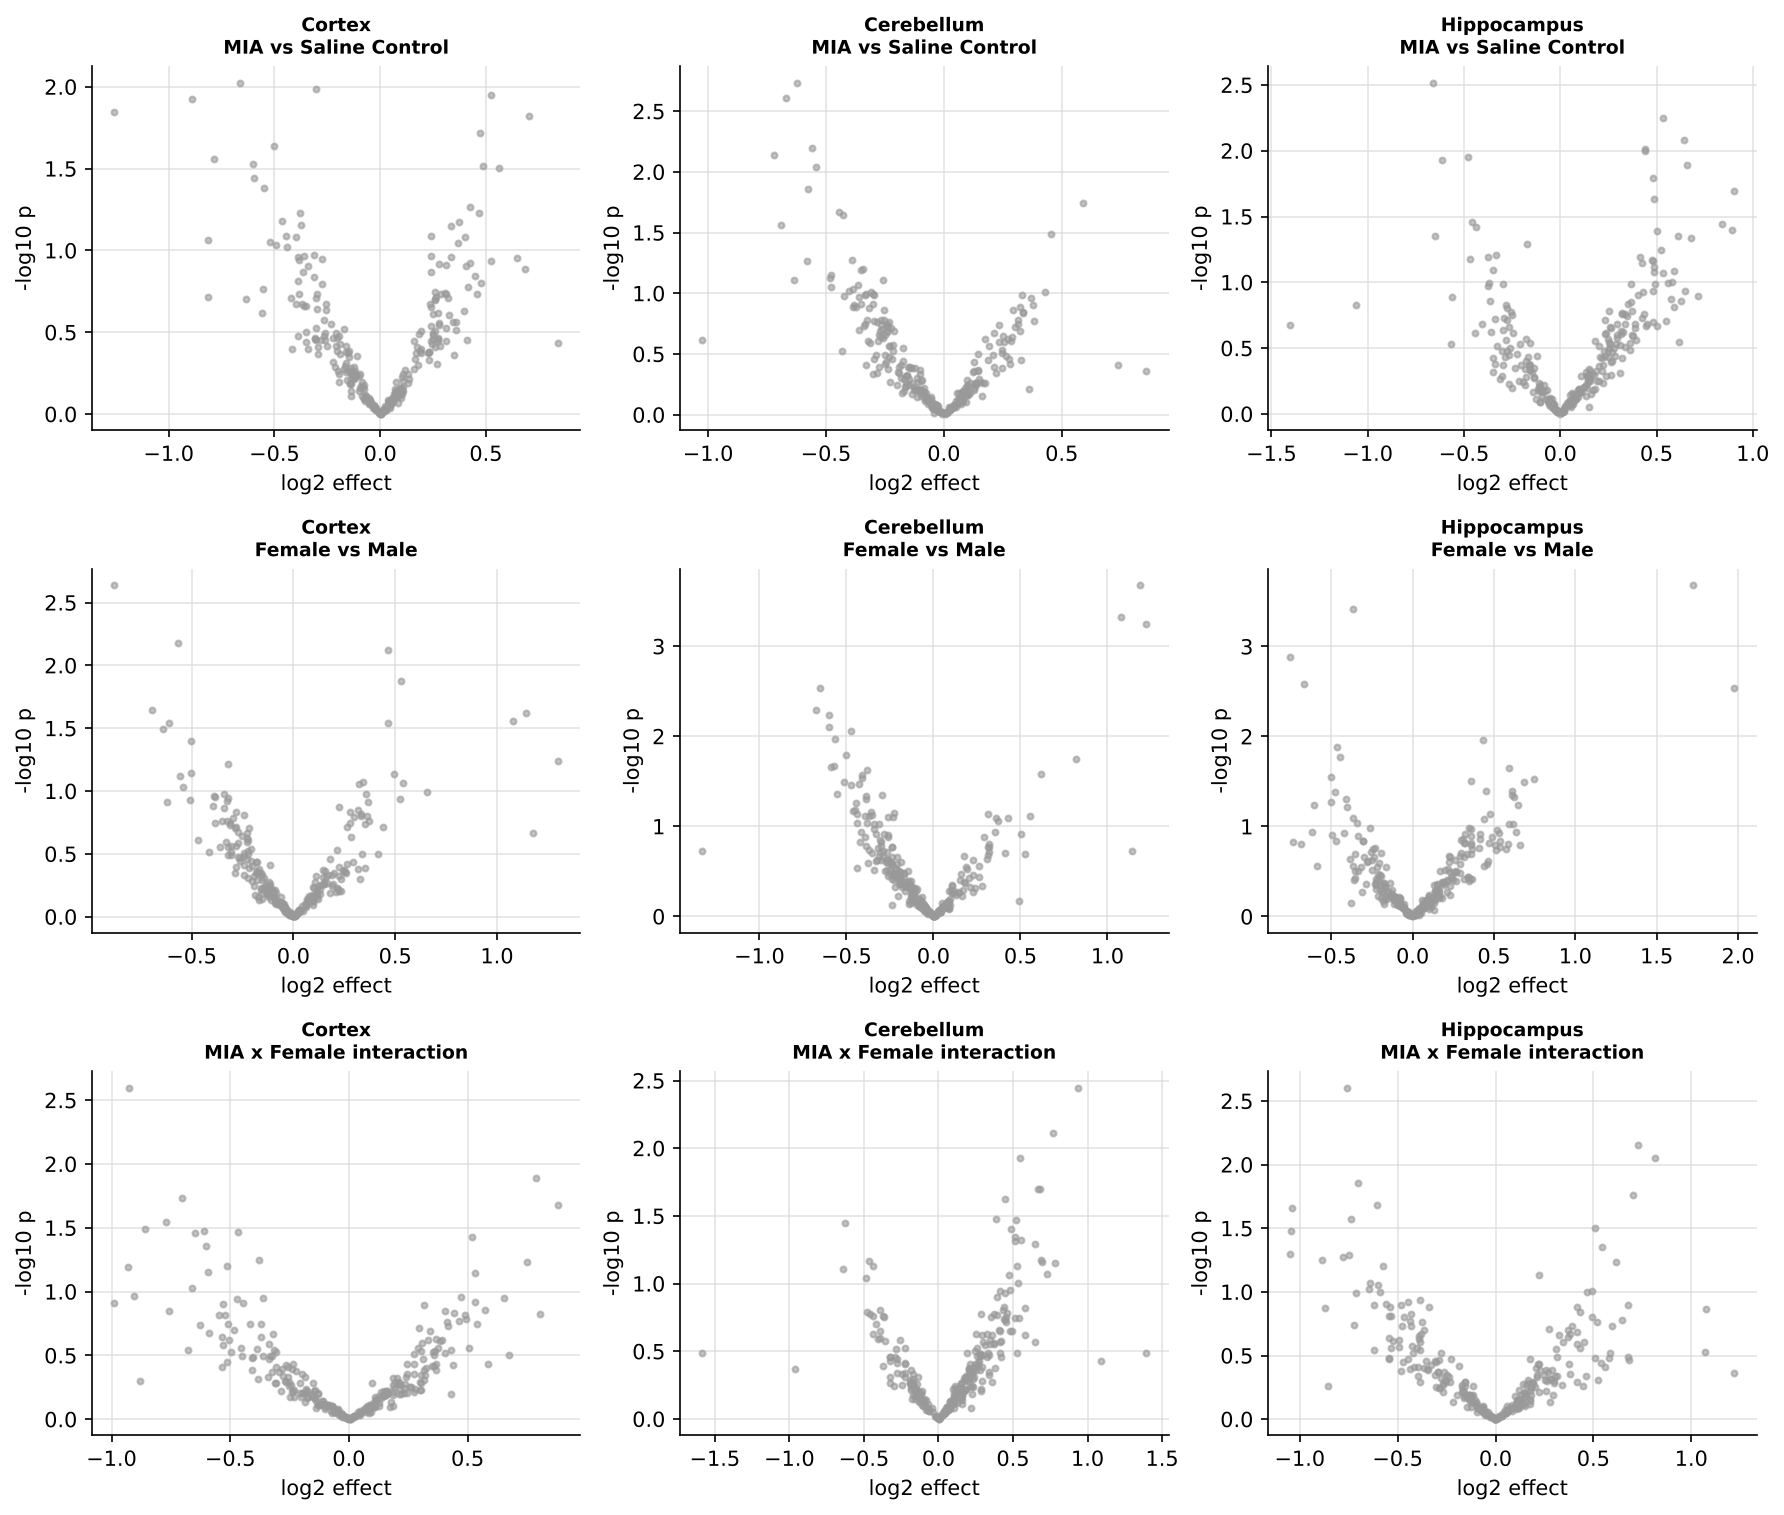

In [14]:
show("lipidomics", "03_differential", "all60", "figures", "volcano_grid.png", width=800)

**Power, stated up front.** The minimum effect detectable with 80 % power is
large. Correlated features also mean far fewer *effective* tests than the panel
size.

In [15]:
display(table("lipidomics", "03_differential", "all60", "detectable_effect_size_summary.csv").head(6))
table("lipidomics", "03_differential", "all60", "effective_number_of_tests.csv")

,Region,power_scale,n_features,median_standard_error,mde_p10_log2,mde_median_log2,mde_p90_log2,observed_n_median,alpha,target_power,illustrative_litter_n,note
0,Cortex,observed_sample_level,282,0.240,0.518,0.672,0.971,20.0,0.05,0.8,NaN,NaN
1,Cortex,illustrative_litter_n,282,0.379,0.819,1.063,1.535,20.0,0.05,0.8,8.0,Illustration only: observed SE rescaled to the...
2,Cerebellum,observed_sample_level,282,0.216,0.459,0.606,0.822,20.0,0.05,0.8,NaN,NaN
3,Cerebellum,illustrative_litter_n,282,0.342,0.725,0.958,1.299,20.0,0.05,0.8,8.0,Illustration only: observed SE rescaled to the...
4,Hippocampus,observed_sample_level,282,0.247,0.493,0.691,1.078,20.0,0.05,0.8,NaN,NaN
5,Hippocampus,illustrative_litter_n,282,0.390,0.779,1.092,1.705,20.0,0.05,0.8,8.0,Illustration only: observed SE rescaled to the...


,Region,n_features_in_panel,Effect,permutation_scheme,n_features_complete_null,n_permutations,nominal_alpha,mean_nominal_discoveries,variance_nominal_discoveries,effective_number_of_tests,effective_tests_status
0,Cortex,282,MIA vs Saline Control,BioGroup within Sex,282,99,0.05,17.606,27.588,168.730,estimated from permutation discovery-count var...
1,Cortex,282,Female vs Male,Sex within BioGroup,282,99,0.05,8.465,11.537,200.692,estimated from permutation discovery-count var...
2,Cortex,282,MIA x Female interaction,BioGroup within Sex,282,99,0.05,13.182,20.660,171.512,estimated from permutation discovery-count var...
3,Cerebellum,282,MIA vs Saline Control,BioGroup within Sex,282,99,0.05,12.394,13.343,250.425,estimated from permutation discovery-count var...
4,Cerebellum,282,Female vs Male,Sex within BioGroup,281,99,0.05,16.343,39.738,108.848,estimated from permutation discovery-count var...
5,Cerebellum,282,MIA x Female interaction,BioGroup within Sex,282,99,0.05,13.929,22.393,166.751,estimated from permutation discovery-count var...
6,Hippocampus,282,MIA vs Saline Control,BioGroup within Sex,282,99,0.05,16.879,25.128,178.085,estimated from permutation discovery-count var...
7,Hippocampus,282,Female vs Male,Sex within BioGroup,282,99,0.05,16.960,21.366,210.383,estimated from permutation discovery-count var...
8,Hippocampus,282,MIA x Female interaction,BioGroup within Sex,282,99,0.05,12.263,18.175,181.989,estimated from permutation discovery-count var...


**The key failure in the thesis: removing outliers creates hits.** For the same
feature and effect, compare the estimate and its standard error with and
without the T²-flagged samples. In the study, a ceramide's sex effect stayed at
1.17 while its standard error dropped from 0.26 to 0.18, and q fell from 0.29 to
0.01. The toy data repeat this. The flagged cortex sample is an MIA mouse, so
the control-group sex estimate cannot move. Only the pooled residual variance
shrinks, and that alone turns the ceramide into a "hit". This is standard-error
shrinkage, not biology.

In [16]:
change = table("lipidomics", "03_differential", "population_comparison", "estimate_vs_standard_error_change.csv")
display(change.groupby(["population", "Region"])["se_ratio"].describe()[["min", "25%", "50%"]].round(2))
table("lipidomics", "03_differential", "population_comparison", "exclusion_dependent_hits.csv")[
    ["population", "Feature", "Region", "Effect", "estimate_log2_all60", "estimate_log2_excluded",
     "standard_error_all60", "standard_error_excluded", "p_value_fdr_all60", "p_value_fdr_excluded"]]

min   25%   50%
population Region                       
t2_95      Cerebellum   0.24  1.03  1.06
           Cortex       0.35  0.81  0.94
           Hippocampus  0.33  0.84  0.99
t2_99      Cerebellum   1.00  1.00  1.00
           Cortex       0.35  0.81  0.94
           Hippocampus  0.35  0.81  0.98

,population,Feature,Region,Effect,estimate_log2_all60,estimate_log2_excluded,standard_error_all60,standard_error_excluded,p_value_fdr_all60,p_value_fdr_excluded
0,t2_95,Cer(d18:0_14:0),Cortex,Female vs Male,1.076,1.076,0.444,0.223,0.902,0.047
1,t2_95,Cer(d18:0_16:0),Cortex,Female vs Male,1.144,1.144,0.458,0.248,0.902,0.047
2,t2_95,Cer(d18:0_18:0),Hippocampus,Female vs Male,1.722,1.338,0.361,0.254,0.054,0.034
3,t2_99,Cer(d18:0_14:0),Cortex,Female vs Male,1.076,1.076,0.444,0.223,0.902,0.047
4,t2_99,Cer(d18:0_16:0),Cortex,Female vs Male,1.144,1.144,0.458,0.248,0.902,0.047
5,t2_99,Cer(d18:0_18:0),Hippocampus,Female vs Male,1.722,1.338,0.361,0.261,0.054,0.035


## 6. Does the answer depend on analysis choices?

* **Specification curve:** prevalence filter x Tech-Mix CV filter x imputation methods.
* **RF/scaling grid:** RF imputation x Pareto scaling x population, with an IQR filter.
  (`Settings.fast` skips the slowest RF arms; `Settings.full` runs them all.)
* **Median vs PQN normalisation.**
* **Litter-aware models:** cage means, a cage random intercept, a collection-date
  effect, the date-matched subset, exact whole-cage permutations and cage ICCs.

sensitivity: 384 s


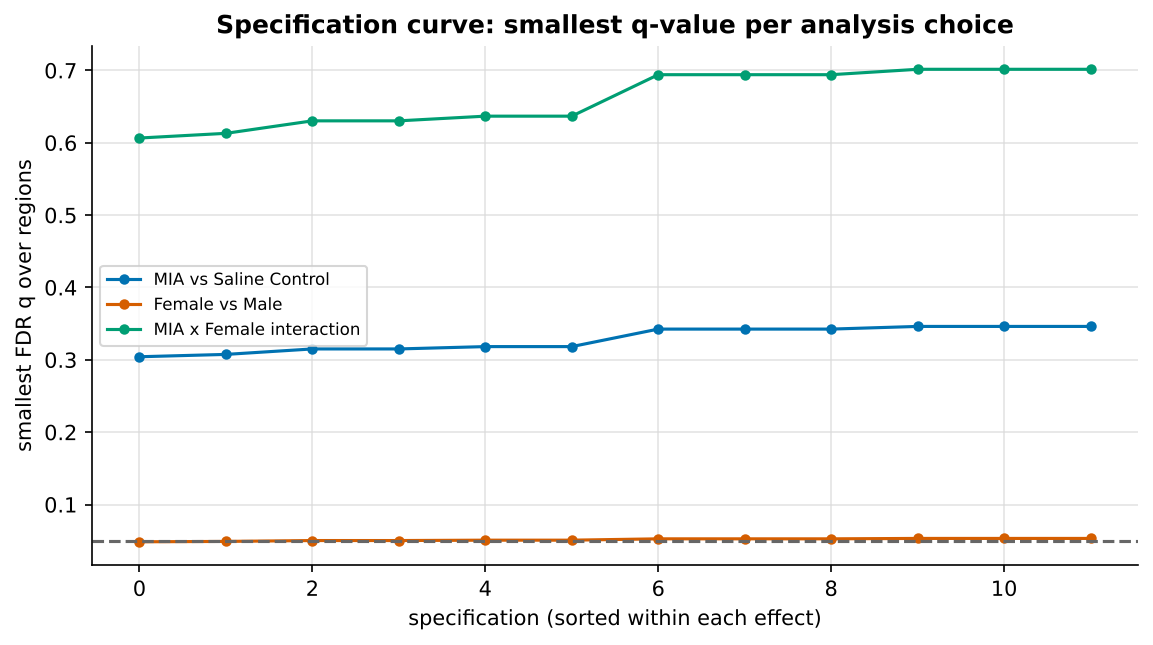

In [17]:
def run_sensitivity():
    sensitivity.specification_curve(settings, "lipidomics")
    sensitivity.rf_variants(settings, "lipidomics")
    for omics in ("lipidomics", "metabolomics"):
        sensitivity.normalization_comparison(settings, omics)
        sensitivity.cage_structure(settings, omics)
step("sensitivity", run_sensitivity, "lipidomics/04_sensitivity/cage_structure/cage_aware_effects.csv")
show("lipidomics", "04_sensitivity", "specification_curve", "figures", "specification_curve.png")

The toy data contain **no MIA effect**, so every MIA "hit" below is a false
positive. The table counts FDR hits (q ≤ 0.05, 282 lipids x 3 regions) for the
naive model and for each litter-aware variant. The last row is the exact
whole-cage permutation, which shuffles the MIA label over the 28 possible
assignments of whole cages and so respects the design exactly.

In [18]:
import json
cage_dir = ("lipidomics", "04_sensitivity", "cage_structure")
arms = json.loads(settings.results_dir.joinpath(*cage_dir, "cage_structure_manifest.json").read_text())["arms"]

naive = table("lipidomics", "03_differential", "all60", "differential_effects.csv")
naive = naive.loc[naive["Effect"].eq("MIA vs Saline Control")]
cage = table(*cage_dir, "cage_aware_effects.csv")
exact = pd.concat([table(*cage_dir, f"cage_permutation_{r.lower()}.csv") for r in config.REGIONS])

rows = [("naive", "group x sex model per region (samples as the unit)", naive["p_value_fdr"].le(0.05).sum(), naive["p_value_fdr"].min())]
rows += [(arm, arms[arm], g["p_value_fdr"].le(0.05).sum(), g["p_value_fdr"].min()) for arm, g in cage.groupby("Arm")]
rows += [("exact", "whole-cage permutation (28 assignments)", exact["p_value_empirical_fdr"].le(0.05).sum(), exact["p_value_empirical_fdr"].min())]
pd.DataFrame(rows, columns=["arm", "model", "n_fdr_hits", "smallest_q"]).round(3)

,arm,model,n_fdr_hits,smallest_q
0,naive,group x sex model per region (samples as the u...,0,0.346
1,A,cage means ~ group (the litter as the unit),1,0.020
2,B,primary model + random intercept per cage,3,0.016
3,C,primary model + collection-date fixed effect,3,0.048
4,D,"group + sex, restricted to the collection date...",0,0.194
5,exact,whole-cage permutation (28 assignments),0,0.537


Model-based litter adjustments are **not enough with 8 litters**. A cage random
intercept (B) or a collection-date term (C) estimates its variance from very
few groups, so their tests are too liberal. Even a plain t-test on cage means
(A) is fragile: the cages hold 1 to 6 mice, so their means are not equally
precise. In each of these arms a few lipids pass FDR although nothing was
planted. Only the exact whole-cage permutation is
calibrated by construction, and it finds nothing. Its smallest possible p-value
is 1/28 ≈ 0.036, so with 282 lipids it *cannot* reach FDR significance at all.
That limit is a property of the design, not of the method.

## 7. A better question: do regional differences persist after MIA?

Region is strong, and every mouse contributes all three regions, so each mouse
is its own control. For each pair of regions we compare the control and MIA
**difference profiles**. The noise-corrected (disattenuated) correlation is 1 if
the regional profile is fully preserved.

region persistence: 94 s


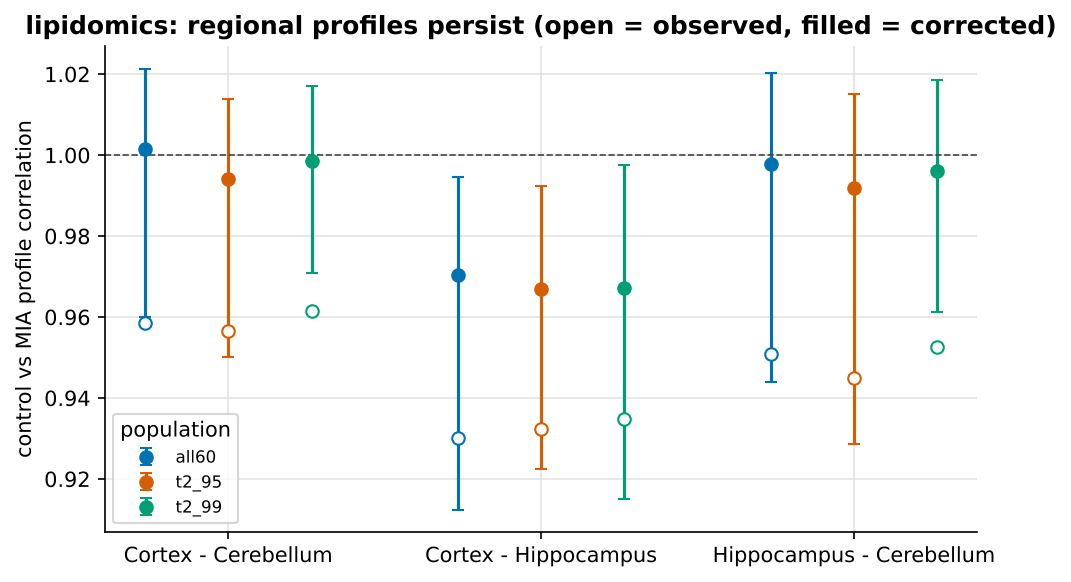

In [19]:
def run_persistence():
    for omics in ("lipidomics", "metabolomics"):
        for population in config.POPULATIONS:
            region_persistence.run(settings, omics, population)
        region_persistence.plot_summary(settings, omics)
step("region persistence", run_persistence, "lipidomics/05_region_persistence/disattenuated_concordance_all.csv")
show("lipidomics", "05_region_persistence", "figures", "disattenuated_concordance.png")

## 8. ASCA+: one multivariate ANOVA instead of hundreds of tests

The data matrix is split into Region, MIA, Sex, their interactions, Mouse and
residual. Each effect gets a variance share and a permutation p-value, with
labels shuffled at the right unit (region within mouse, whole litters for MIA).

ASCA+: 108 s


,Engine,Effect,variance_share,p_value,n_permutations
0,Region,Region,0.501,0.010,100
3,Group (cage),Group,0.014,0.536,28
4,Group (cage),Region:Group,0.015,0.964,28
9,Group (mouse),Group,0.014,0.020,100
10,Group (mouse),Region:Group,0.015,0.740,100
15,Sex,Sex,0.012,0.210,100
16,Sex,Region:Sex,0.017,0.350,100


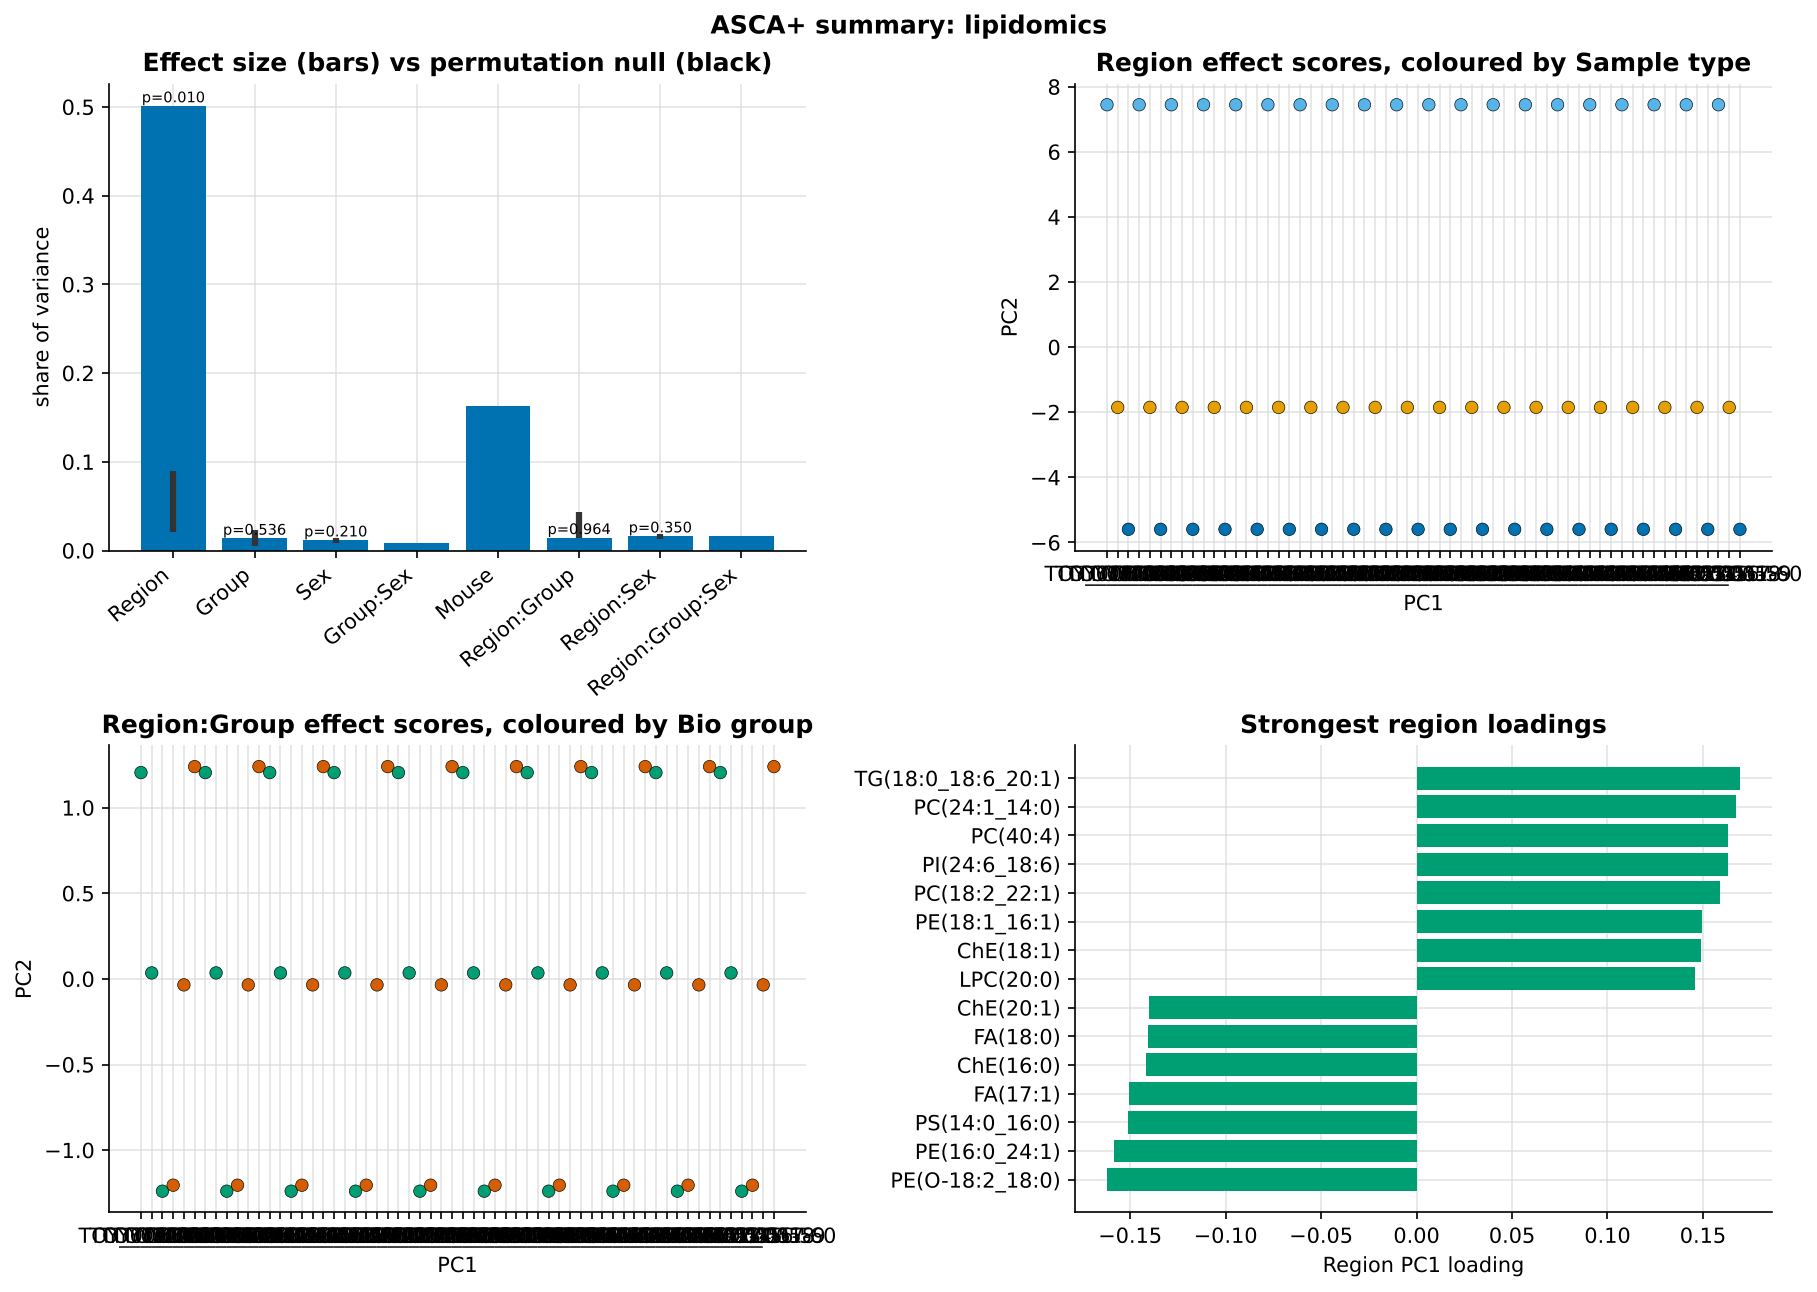

In [20]:
# the notebook fits the primary population; pipeline.run_all also fits t2_95 and t2_99
step("ASCA+", lambda: [asca.run(settings, omics, "all60") for omics in ("lipidomics", "metabolomics")],
     "lipidomics/06_asca/all60/permutation_tests.csv")
tests = table("lipidomics", "06_asca", "all60", "permutation_tests.csv")
display(tests.loc[tests["Scaling"].eq("autoscaled"), ["Engine", "Effect", "variance_share", "p_value", "n_permutations"]])
show("lipidomics", "06_asca", "all60", "figures", "asca_composite.png", width=800)

Region explains about half of the variance, and its p-value is at the floor of
the permutation test. For MIA, compare the two *Group* rows. They test the same
variance share with different shuffle units:

* **Group (mouse):** shuffles MIA labels between individual mice. Mice from one
  litter share a mother and a cage, so they are not independent. The small
  litter differences planted in the toy data are then mistaken for a treatment
  effect, which gives a small p-value although MIA does nothing.
* **Group (cage):** shuffles whole litters, the true experimental unit. The
  same variance share is now unremarkable.

Section 10 measures this inflation directly with simulated noise.

## 9. Beyond p-values: effect sizes

When a litter-level p-value can never go below 1/28, it helps more to ask how
large an effect could be. The stage covers pre-defined lipid composites (myelin
index, DHA share, Cer:SM, ...), protein sets, leave-one-litter-out ranges, and
which fold changes the intervals already rule out.

effect sizes: 12 s


,Region,n_lipids,median_abs_fold_change,share_ci_excludes_gt_1.25x,share_ci_excludes_gt_1.5x,share_ci_excludes_gt_2.0x
0,Cerebellum,282,1.080,0.131,0.848,0.982
1,Cortex,282,1.090,0.064,0.660,0.957
2,Hippocampus,282,1.091,0.085,0.642,0.950


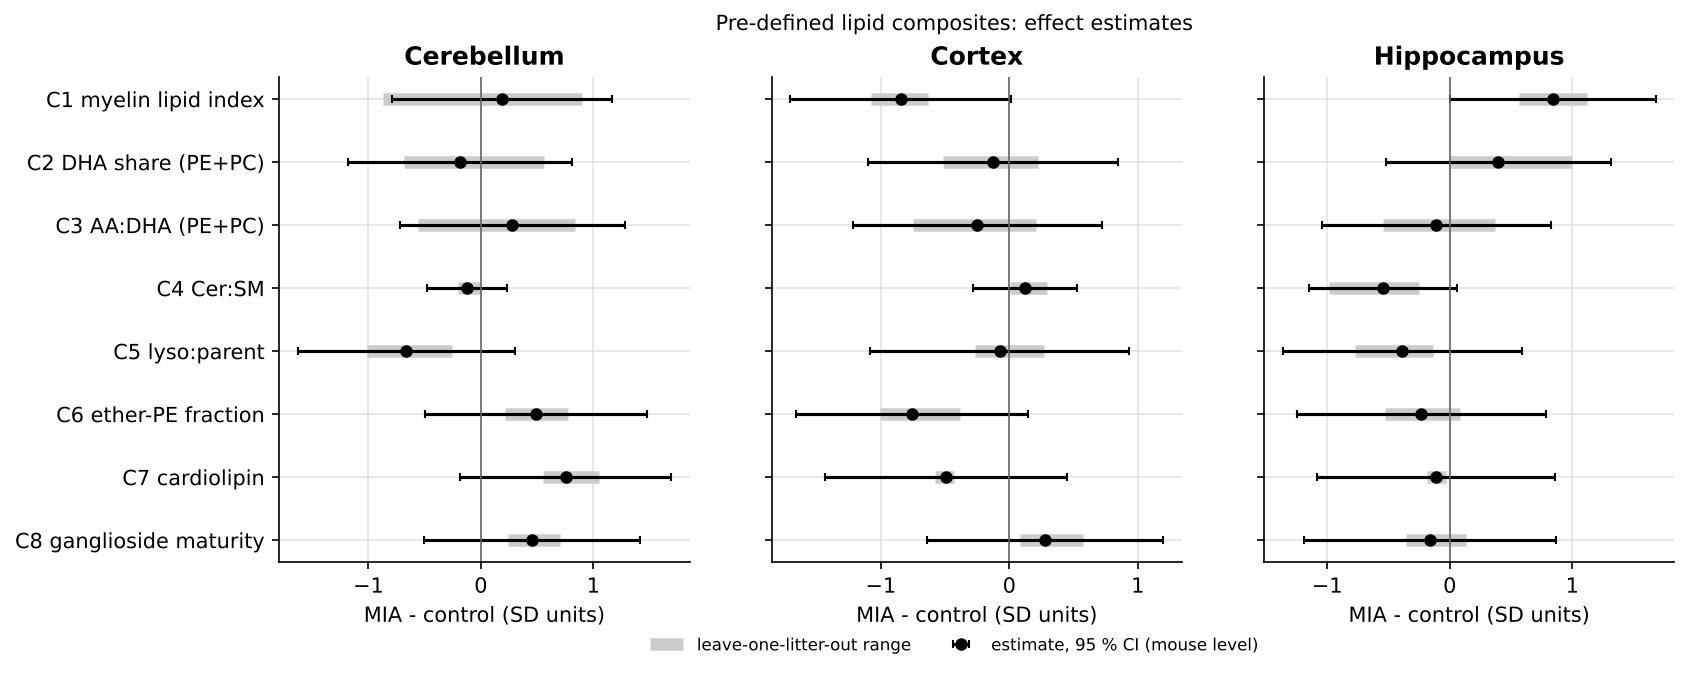

In [21]:
step("effect sizes", lambda: effect_sizes.run(settings), "integration/07_effect_sizes/all60/lipid_composites.csv")
display(table("integration", "07_effect_sizes", "all60", "effects_ruled_out.csv"))
show("integration", "07_effect_sizes", "all60", "figures", "composite_effects_forest.png", width=800)

## 10. Multi-omics integration

The three omics are joined on the same 60 samples. Region is the known positive
control and MIA the characterised negative, so the question for every method
is: **does it find region, and does it correctly find nothing for MIA?**

In [22]:
blocks, block_meta, _ = integration.build_blocks(settings)
{view: block.shape for view, block in blocks.items()}

{'lipidomics': (60, 111), 'metabolomics': (60, 55), 'proteomics': (60, 700)}

MOFA+ (all samples): 5 s


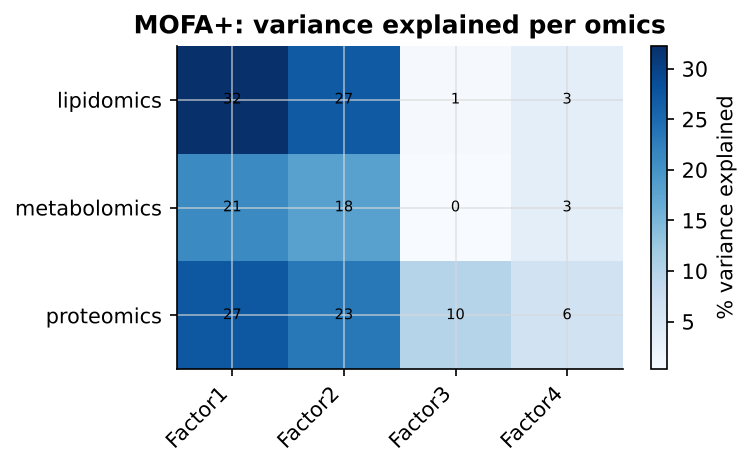

Covariate,Bio group,Cage,Collection cohort,Sample type,Sex,Tissue mass (mg)
Factor,,,,,,
Factor1,0.00,0.00,0.00,1.00,0.00,0.00
Factor2,0.00,0.00,0.00,1.00,0.00,0.02
Factor3,0.00,0.51,0.21,0.00,0.99,0.03
Factor4,0.01,0.10,0.04,0.02,0.00,0.01


,Score name,mouse_permutation_p,cage_permutation_p,group_r_squared,cage_r_squared,treatment_associated
0,mofa:Factor1,0.863,0.893,1.536e-03,3.321e-03,False
1,mofa:Factor2,0.674,0.821,1.028e-02,4.374e-04,False
2,mofa:Factor3,0.142,0.821,3.505e-04,2.203e-04,False
3,mofa:Factor4,0.502,0.464,2.590e-02,2.903e-02,False


In [23]:
step("MOFA+ (all samples)", lambda: integration.run_mofa(settings), "integration/01_mofa/variance_explained.csv")
show("integration", "01_mofa", "figures", "variance_explained.png")
display(table("integration", "01_mofa", "factor_associations.csv").pivot(index="Factor", columns="Covariate", values="r_squared").round(2))
table("integration", "01_mofa", "mia_tests.csv")[["Score name", "mouse_permutation_p", "cage_permutation_p", "group_r_squared", "cage_r_squared", "treatment_associated"]]

A factor can separate MIA from control at the mouse level and still fail at
the litter level. If the litter explains more of a score than the treatment
does (cage R² > group R²), the "MIA effect" cannot be told apart from litter or
collection date.

**Within region.** A multi-group MOFA+ with region means removed asks what mice
share *inside* a region. The toy data hide three such programmes: sex-linked
proteins, a "myelin" module and an "energy" module.

MOFA+ within region: 4 s


,Factor,n_recovered,n_seeds,median_abs_correlation,stable
0,Factor1,4,5,1.0,True
1,Factor2,5,5,1.0,True
2,Factor3,4,5,1.0,True


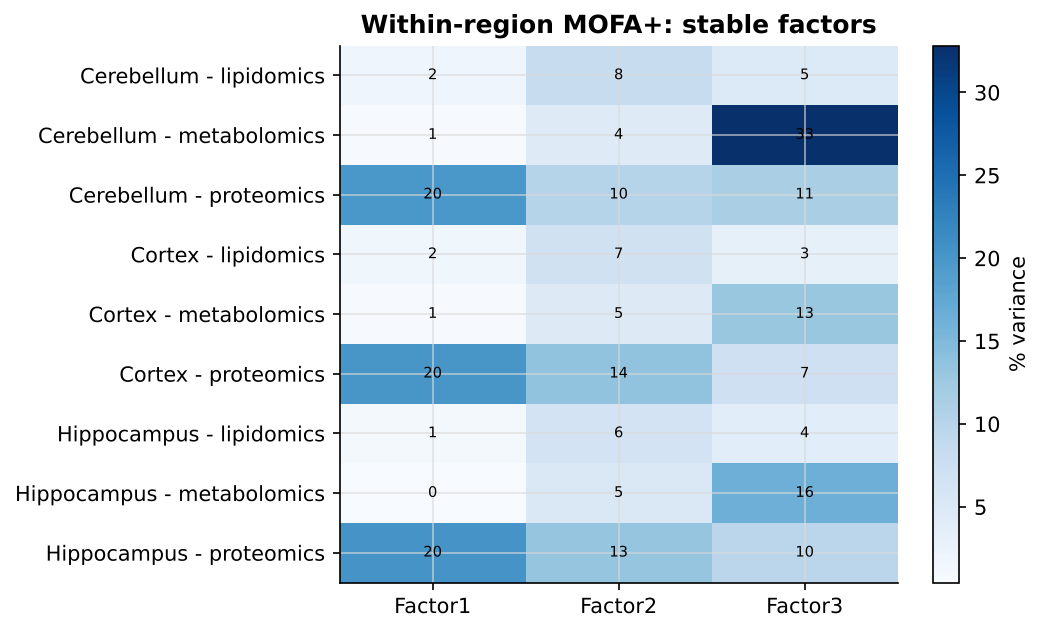

In [24]:
step("MOFA+ within region", lambda: integration.run_mofa_within_region(settings), "integration/02_mofa_within_region/factor_stability.csv")
display(table("integration", "02_mofa_within_region", "factor_stability.csv"))
show("integration", "02_mofa_within_region", "figures", "variance_stable_factors.png")

In [25]:
step("benchmark", lambda: integration.run_benchmark(settings), "integration/03_benchmark/region_recovery.csv")
step("cross-omics screen", lambda: integration.run_cross_omics_screen(settings), "integration/04_cross_omics_screen/modules.csv")
step("enrichment", lambda: integration.run_enrichment(settings), "integration/05_enrichment/protein_enrichment.csv")
step("covariate map", lambda: integration.run_covariate_map(settings), "integration/06_covariate_map/axis_covariate_r2.csv")
display(table("integration", "03_benchmark", "region_recovery.csv"))
display(table("integration", "04_cross_omics_screen", "association_counts_vs_null.csv"))
enrich = table("integration", "05_enrichment", "protein_enrichment.csv")
enrich.sort_values("q_value").groupby("unit").head(1)[["unit", "term", "n_overlap", "q_value", "overlap_genes"]]

benchmark: 9 s


cross-omics screen: 21 s


enrichment: 3 s


covariate map: 1 s


,method,metric,mean,sd
0,concatenated_pca,region accuracy (mouse-grouped CV),1.0,0.0
1,block_pls,region accuracy (mouse-grouped CV),1.0,0.0


,Region,target_view,observed_pairs,null_mean,null_z,pairing_shuffle_p
0,Cerebellum,metabolomics,108,11.60,16.625,0.048
1,Cortex,metabolomics,29,11.35,4.029,0.048
2,Hippocampus,metabolomics,61,11.75,9.801,0.048
3,Cerebellum,proteomics,545,153.40,16.823,0.048
4,Cortex,proteomics,379,155.55,7.647,0.048
5,Hippocampus,proteomics,547,164.05,12.748,0.048


,unit,term,n_overlap,q_value,overlap_genes
1521,Cerebellum module 9,Myelination [R-TOY-12],10,5.293e-08,Cldn11;Cnp;Mag;Mal;Mbp;Mobp;Mog;Opalin;Plp1;Ugt8
836,Cerebellum module 2,MYELINATION%GOBP%GO:0042552,10,5.293e-08,Cldn11;Cnp;Mag;Mal;Mbp;Mobp;Mog;Opalin;Plp1;Ugt8
609,Cerebellum module 17,Myelination [R-TOY-12],10,5.293e-08,Cldn11;Cnp;Mag;Mal;Mbp;Mobp;Mog;Opalin;Plp1;Ugt8
4637,Hippocampus module 18,Myelination [R-TOY-12],10,7.291e-08,Cldn11;Cnp;Mag;Mal;Mbp;Mobp;Mog;Opalin;Plp1;Ugt8
5549,Hippocampus module 29,Myelination [R-TOY-12],10,7.291e-08,Cldn11;Cnp;Mag;Mal;Mbp;Mobp;Mog;Opalin;Plp1;Ugt8
...,...,...,...,...,...
5720,Hippocampus module 4,TOY RANDOM PROCESS 4%GOBP%GO:9900004,0,1.000e+00,NaN
5784,Hippocampus module 5,TOY RANDOM PROCESS 2%GOBP%GO:9900002,0,1.000e+00,NaN
5944,Hippocampus module 7,TOY RANDOM PROCESS 3%GOBP%GO:9900003,0,1.000e+00,NaN
6008,Hippocampus module 8,Toy Random Process 13 [R-TOY-28],1,1.000e+00,Gene0438


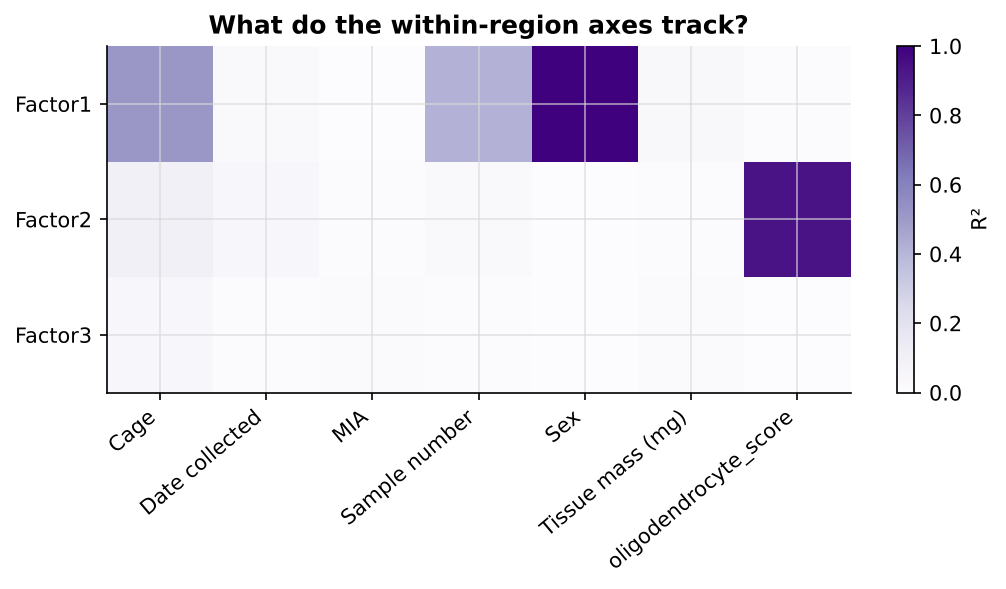

In [26]:
show("integration", "06_covariate_map", "figures", "covariate_map.png")

**Why tests are done at the litter level.** Simulated pure-noise scores, with
and without a shared litter offset, show how often each test falsely rejects.

In [27]:
step("inference checks", lambda: integration.run_inference_checks(settings), "integration/09_inference_checks/false_positive_rates.csv")
table("integration", "09_inference_checks", "false_positive_rates.csv")

inference checks: 10 s


,litter_effect,mouse_permutation_false_positive_rate,cage_permutation_false_positive_rate
0,False,0.10,0.0
1,True,0.25,0.0


## 11. Reproducing the facility's report figures

The core facility's report showed PLS-DA score plots in which the groups looked
well separated. A supervised method separates groups even when they do not
differ, which is what the permutation test checks.

vendor figures: 18 s


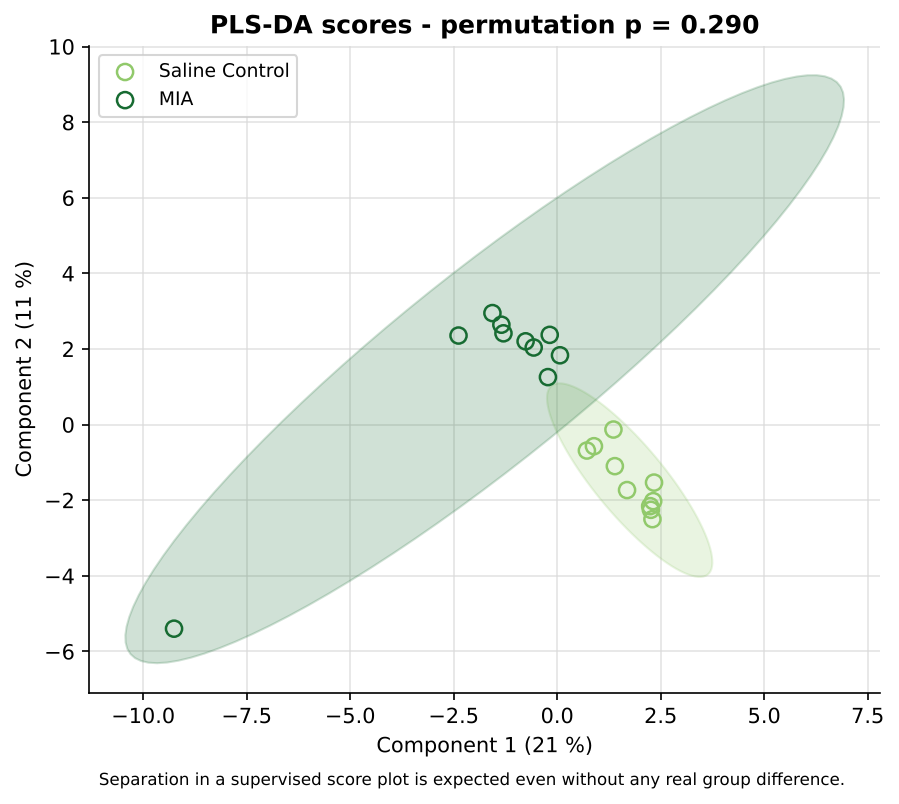

In [28]:
step("vendor figures", lambda: vendor_figures.run(settings), "lipidomics/09_vendor_figures/plsda_permutation_tests.csv")
show("lipidomics", "09_vendor_figures", "plsda_cortex.png", width=480)

## 12. The whole pipeline in one call

Everything above is what `pipeline.run_all` does, step by step. From a terminal:

```bash
python -m mia_multiomics.pipeline --fast            # this notebook's settings
python -m mia_multiomics.pipeline                   # full-size run
python -m mia_multiomics.pipeline --fast --only qc outliers differential
```

In [29]:
from mia_multiomics.pipeline import STEPS
pd.DataFrame([(name, description) for name, description, _ in STEPS], columns=["step", "what it does"])

,step,what it does
0,qc,"preprocessing log, pooled QC, missingness, des..."
1,noise_floor,abundance-similarity noise floor (lipidomics)
2,feature_modules,feature-space PCA and co-abundance modules
3,outliers,regional PCA outlier screen (defines t2_95 / t...
4,outlier_ensemble,calibrated multi-detector outlier ensemble
5,outlier_concordance,do the two assays flag the same samples?
6,differential,"group x sex model per region, all three popula..."
7,sensitivity,"specification curve, RF/scaling grid, PQN, lit..."
8,region_persistence,do regional profiles persist after MIA?
9,asca,ASCA+ multivariate ANOVA with permutation tests


## Summary

* Region is a large, reproducible signal in every omics and every method: the positive control works.
* No method finds a robust MIA effect. Apparent hits come from sample exclusion
  (standard-error shrinkage), from treating mice as independent, or from model-based
  litter adjustments with too few litters. The exact whole-cage permutation removes all of them.
* The shared within-region programmes planted in the toy data are found by MOFA+
  and the cross-omics screen, and enrichment of their proteins points to the right gene sets.
* With 20 mice in 8 litters, the most useful honest outputs are effect sizes, detectable-effect
  bounds and litter-level permutation tests.